# TUTORIAL: Bias-aware data assimilation on the Rijke tube


In [1]:
from romda.utils import set_working_directories
data_folder, results_folder = set_working_directories('rijke/')[:2]


...Applying manual bias: linear


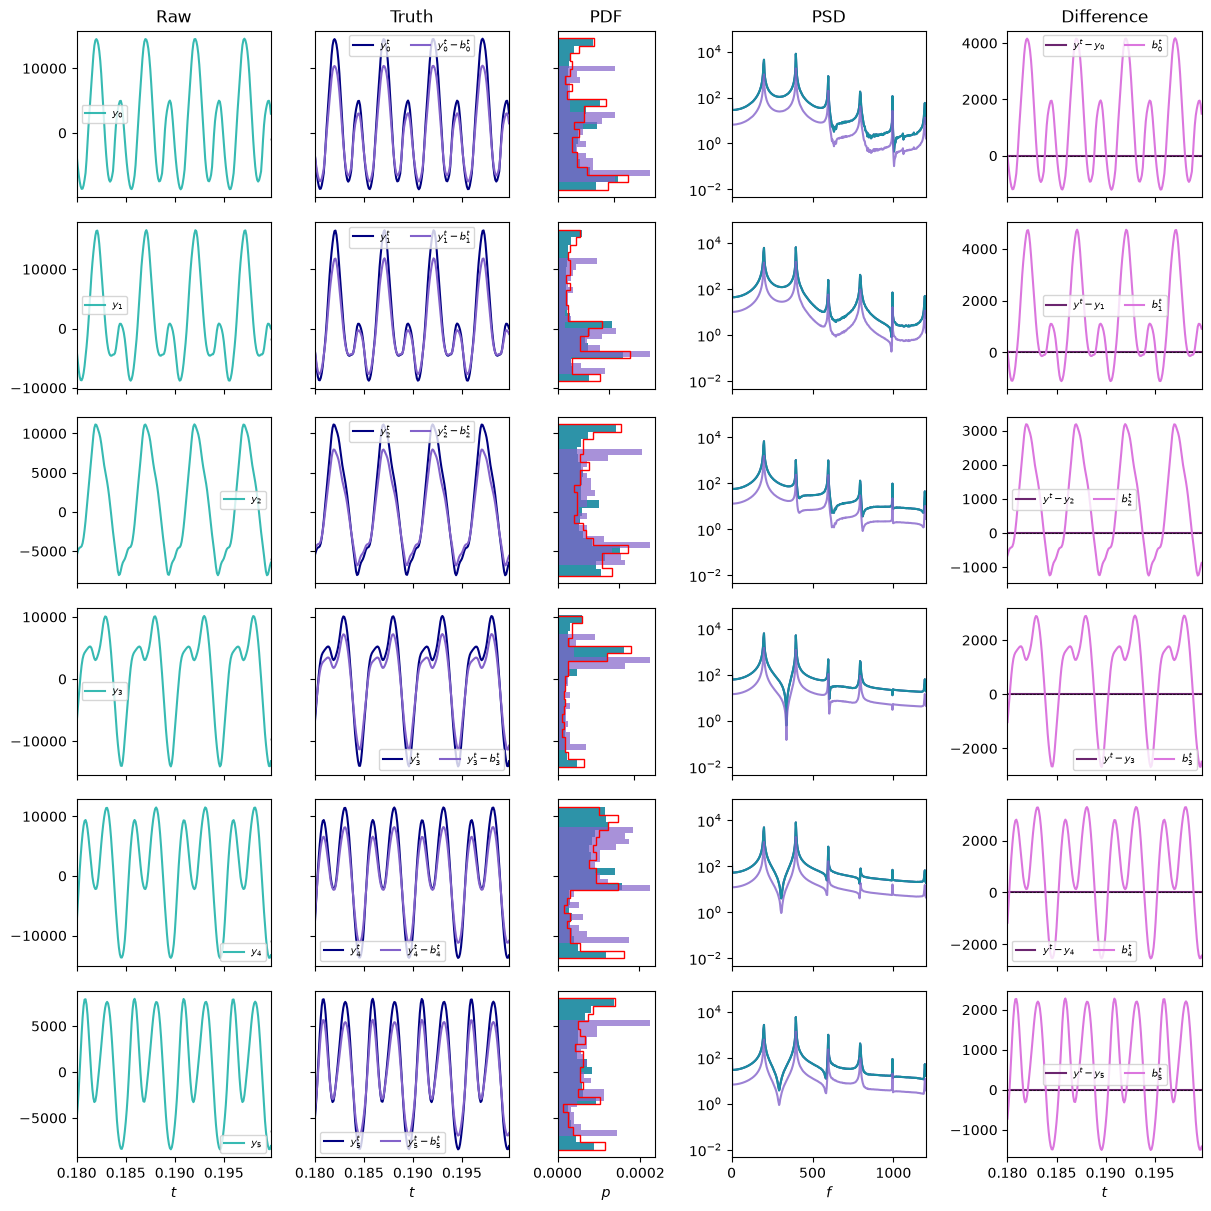

In [2]:
from romda.models.physical import Rijke
from romda.observations import Observations

truth = Observations(model=Rijke,
                     manual_bias='linear',
                     t_start=.2,
                     t_stop=.6,
                     Nt_obs=20)

truth.plot_truth(truth, f_max=1200, window=0.02, fig_width=12)

dynamodels/model.py:393: UserWarning: psi0 is being re-assigned. Previous shape (30, 1), new shape (70, 1). This is not recommended.
  warnings.warn(f"psi0 is being re-assigned. Previous shape {self._psi0.shape},"


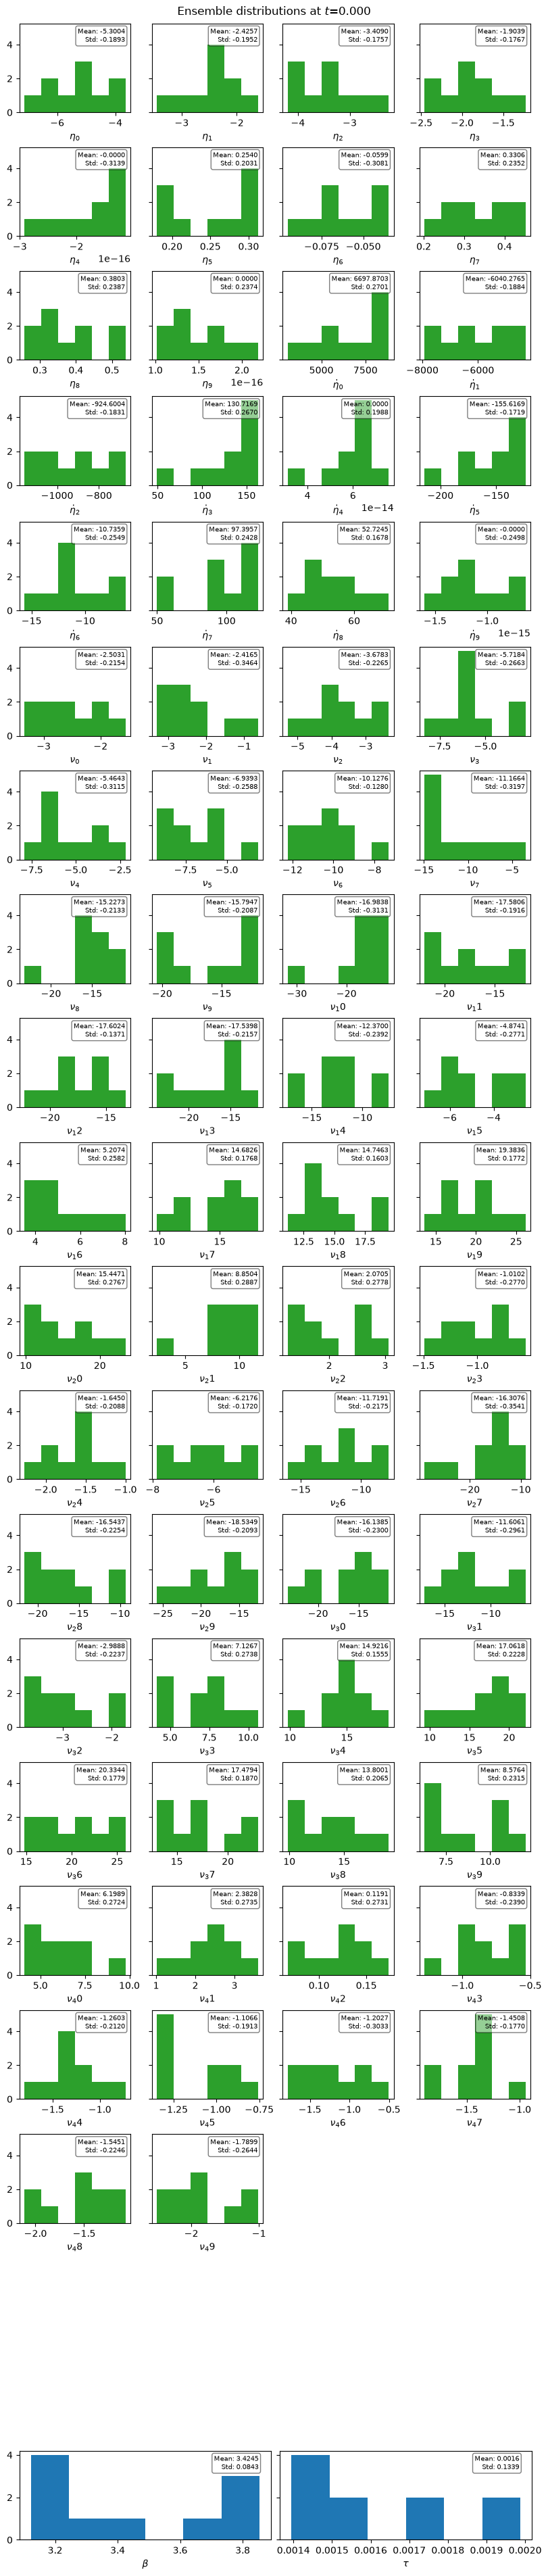

In [3]:
from romda.estimators import rBA_EnKF, EnKF, EnSRKF


ensemble = rBA_EnKF(parent_model=Rijke(dt=truth.dt),
                    bias_regularization=1.,
                    m=10,
                    std_phi=0.25,
                    std_alpha=dict(beta=[3., 4.],
                                   tau=[1e-3, 2e-3]),
                    distribution_alpha='uniform',
                    inflation=1.0,
                    inflation_factor_rejection=1.005,
                    )

ensemble.visualize_state()

In [4]:
from romda.bias_estimators import ESN_bias
import numpy as np

training_data_filename = f"{results_folder}/ESN_train_data_rijke_{truth.name_bias}"

bias_estimator = ESN_bias(rom=ensemble.model,
                          reference_data=truth,
                          training_data_filename=training_data_filename,
                          # Training data generation options
                          augment_data=True,
                          biased_observations=False,
                          correlation_based_training=False,
                          L=20,
                          std_alpha=0.3,
                          # Training, validation and test times
                          t_val=0.02,
                          t_train=0.25,
                          t_test=0.06,
                          N_units=100,
                          N_wash=15,
                          upsample=2,
                          # Hyperparameter search ranges
                          rho_range=(0.2, 1.0),
                          tikh_range=[1e-16],
                          sigma_in_range=(np.log10(1e-5), np.log10(1e-2)),
                          plot_training=True,
                          N_ens=10,
                          )

✓ Found matching config: cb2c61a97ac2ac82
Configuration loaded from ...results/esn_configs/cb2c61a97ac2ac82/esn_config.yaml


In [5]:
filter_ens = ensemble.copy()
filter_ens.bias = bias_estimator.copy()
filter_ens.regularization_factor = 1.

# Observation error covariance matrix
std_obs = 0.1
Cdd = np.diag(std_obs * np.ones(filter_ens.model.Nq)) * np.max(abs(truth.y_obs), axis=0) ** 2

for d, t_d in zip(truth.y_obs, truth.t_obs):
    filter_ens.forecast_step(t_end=t_d)
    filter_ens.analysis_step(d=d, Cdd=Cdd.copy())

# Forecast beyond the last observation and close the multiprocessing pools
filter_ens.forecast_step(t_end=truth.t_obs[-1] + 10 * filter_ens.model.t_CR, close=True)

Initializing multiprocessing pool for IVPIntegrator with m=10 and 10 pools.


Non-physical analysis: 1/39
Non-physical analysis: 2/40
Non-physical analysis: 3/41
Non-physical analysis: 4/42
Non-physical analysis: 5/43


Non-physical analysis: 6/44
Non-physical analysis: 7/45
Non-physical analysis: 8/46
Non-physical analysis: 9/47
Non-physical analysis: 10/48
Non-physical analysis: 11/49


Non-physical analysis: 12/50
Non-physical analysis: 13/51
Non-physical analysis: 14/52
Non-physical analysis: 15/53
Non-physical analysis: 16/54


Non-physical analysis: 17/55
Non-physical analysis: 18/56
Non-physical analysis: 19/57
Non-physical analysis: 20/58
Non-physical analysis: 21/59
Non-physical analysis: 22/60


Non-physical analysis: 23/61
Non-physical analysis: 24/62
Non-physical analysis: 25/63
Non-physical analysis: 26/64
Non-physical analysis: 27/65
Non-physical analysis: 28/66


... (31 outputs left out)

Non-physical analysis: 151/189
Non-physical analysis: 152/190
Non-physical analysis: 153/191
Non-physical analysis: 154/192


Non-physical analysis: 155/193
Non-physical analysis: 156/194
Non-physical analysis: 157/195
Non-physical analysis: 158/196


Non-physical analysis: 159/197
Non-physical analysis: 160/198
Non-physical analysis: 161/199
Non-physical analysis: 162/200


Non-physical analysis: 163/201


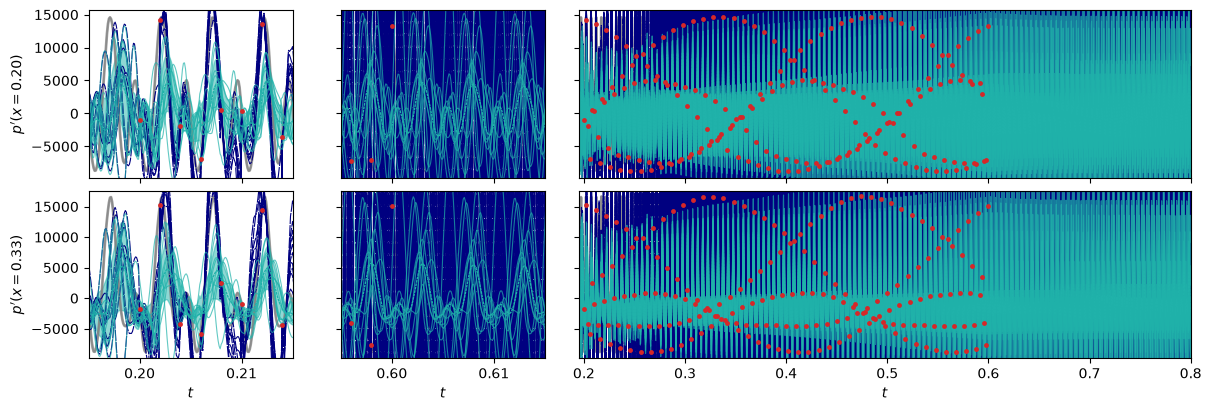

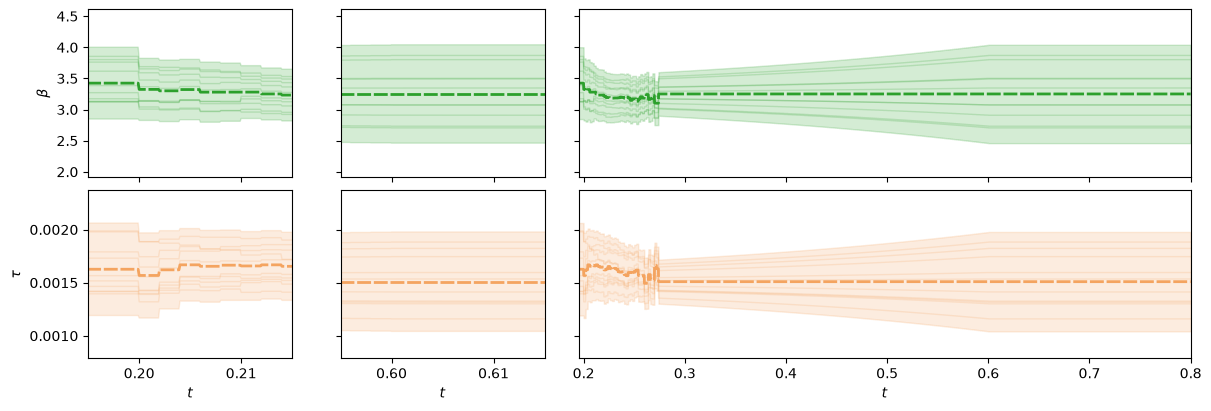

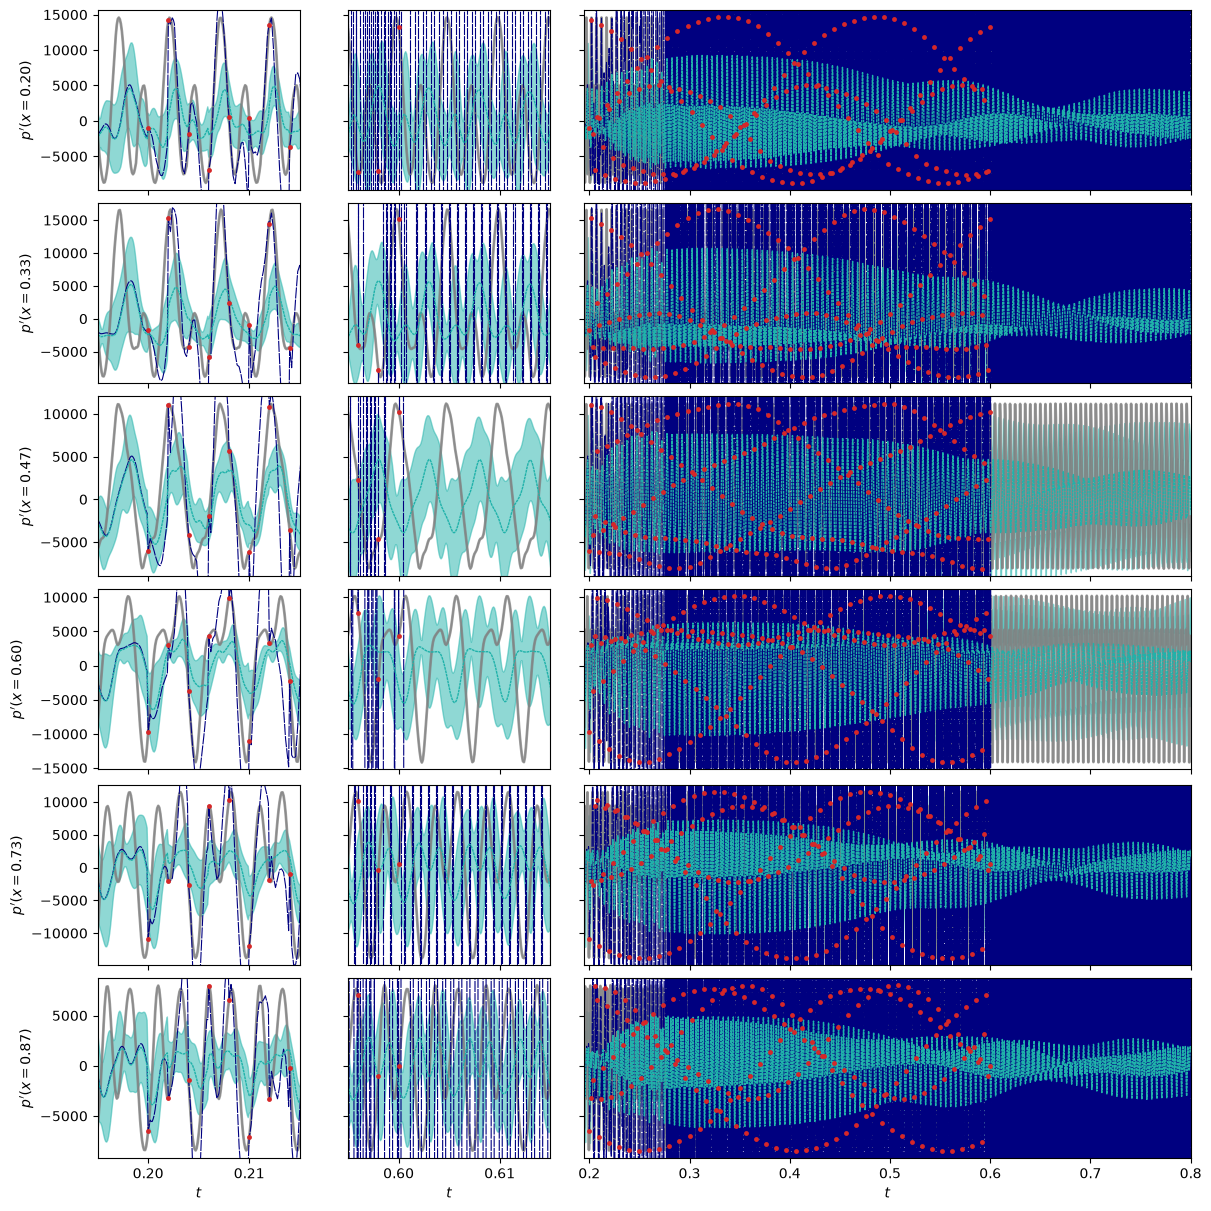

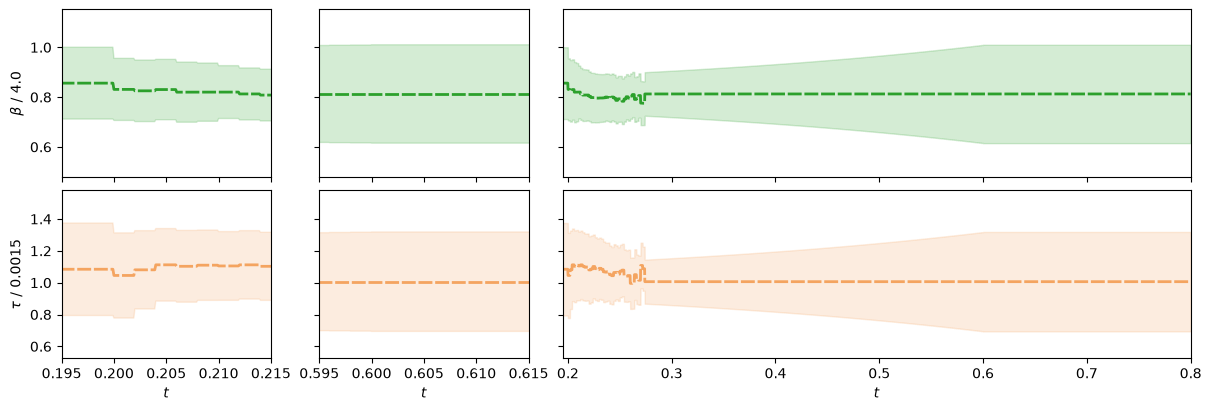

In [6]:
filter_ens.visualize_history(truth=truth, plot_members=True, dims=[0, 1])
filter_ens.visualize_history(truth=truth, plot_members=False, reference_a=truth.true_parameters)

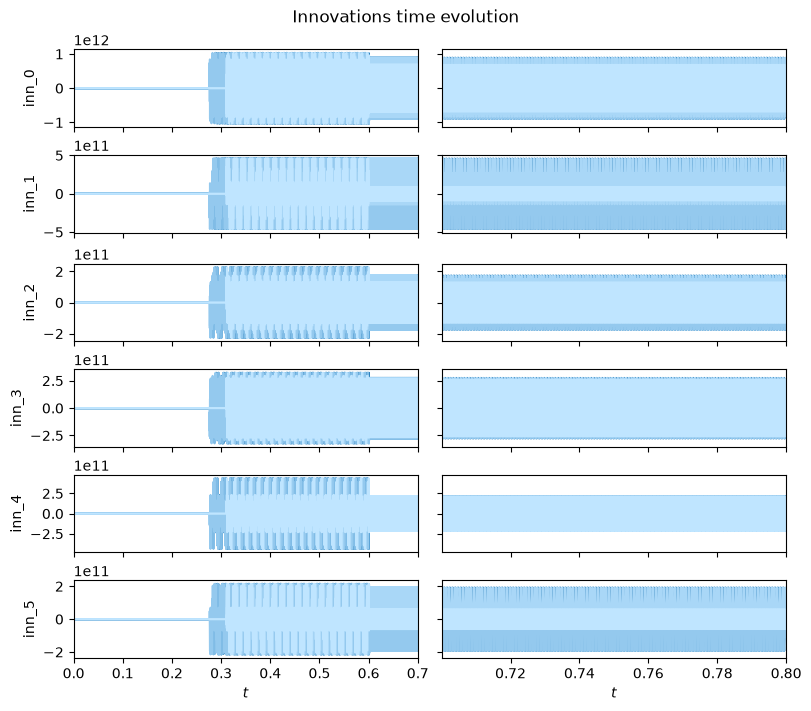

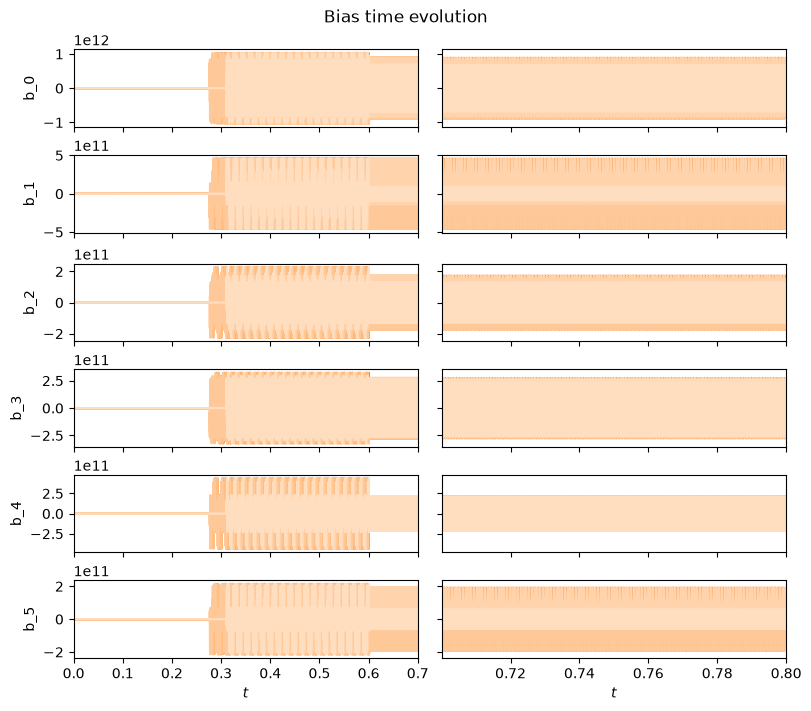

In [7]:
# Visualize the estimated bias and innovations over the assimilation window
filter_ens.bias.visualize_bias_and_innovations(plot_members=True)